In [27]:
import os
import random
import time
import io
import copy
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

print("PyTorch version:", torch.__version__)
print("Available GPUs:", torch.cuda.device_count())


# Reproducibility (individual training runs also use seeded DataLoader shuffling)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

OUTPUT_DIR = "assignment_results"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Fixed epoch budgets for a fair comparison (assignment: custom models >=20 epochs)
OPTIMIZER_EPOCHS = 20
CUSTOM_EPOCHS = 70
PRETRAINED_EPOCHS = 20
BATCH_SIZE = 32

PyTorch version: 2.14.0+cu130
Available GPUs: 1


In [28]:
import torchvision

print("Torchvision version:", torchvision.__version__)

Torchvision version: 0.29.1+cpu


In [29]:
# Load the TF-Flowers dataset
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.transforms import InterpolationMode
from itertools import islice

data_dir = "data/flower_photos"

ds_raw = datasets.ImageFolder(data_dir)

# Get the class names
class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]
ds_raw.target_transform = lambda label: class_names.index(ds_raw.classes[label])

print("Dataset loaded successfully!")
print("Number of images:", len(ds_raw))
print("Number of classes:", len(class_names))
print("Class names:", class_names)

Dataset loaded successfully!
Number of images: 3670
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


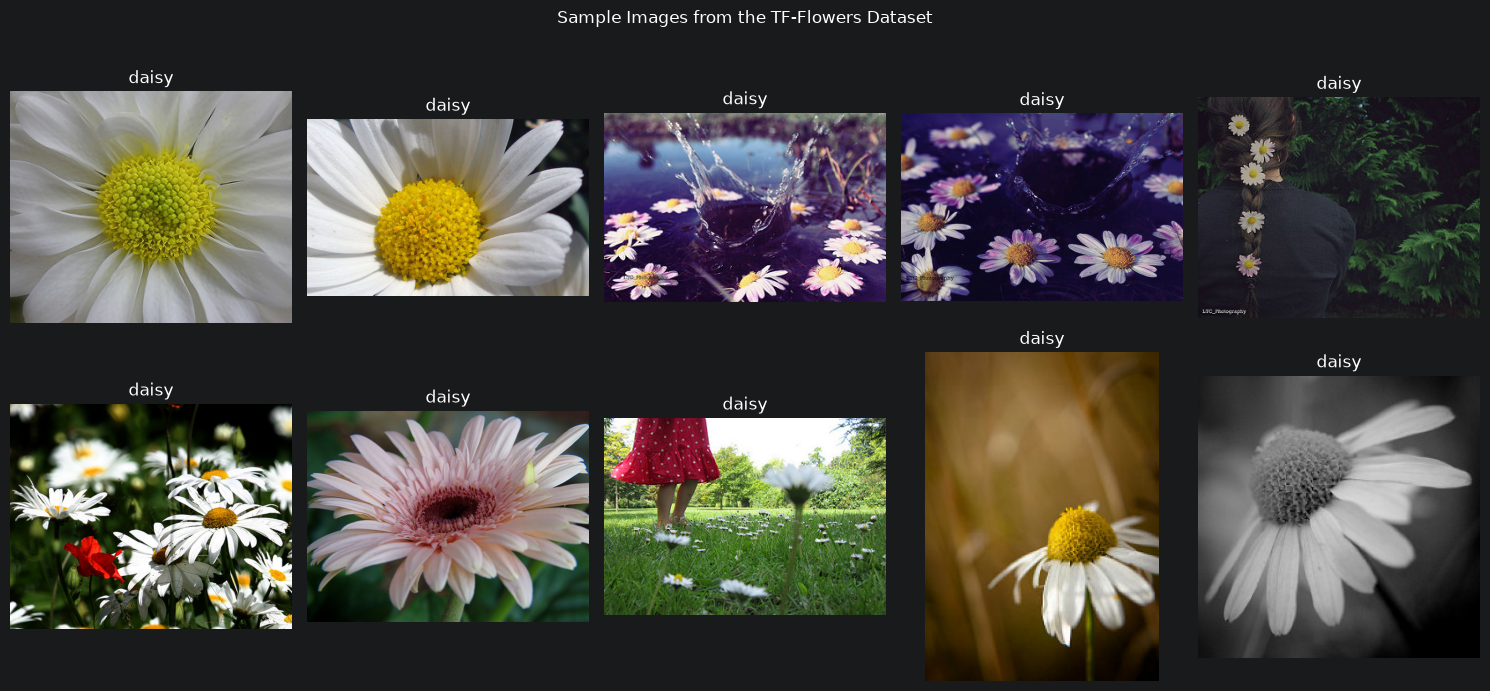

In [30]:
# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, (image, label) in enumerate(
    islice(ds_raw, 10)
):
    row = i // 5
    col = i % 5

    axes[row, col].imshow(image)
    axes[row, col].set_title(class_names[label])
    axes[row, col].axis("off")

plt.suptitle("Sample Images from the TF-Flowers Dataset")
plt.tight_layout()
plt.show()

In [31]:
# Inspect the dimensions of the first image
for image, label in islice(ds_raw, 1):
    image = np.array(image)
    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())

Image shape: (263, 320, 3)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 238


In [32]:
# Step 4: Resize all images to 64 x 64

IMAGE_SIZE = (64, 64)

images = []
labels = []

for image, label in ds_raw:

    # Resize the image
    image = transforms.functional.resize(
        transforms.functional.pil_to_tensor(image).float(),
        IMAGE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    )

    # Convert to uint8
    image = image.permute(1, 2, 0).byte().numpy()

    images.append(image)
    labels.append(int(label))

# Convert lists to NumPy arrays
X = np.stack(images)
y = np.array(labels, dtype=np.int64)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Image data type:", X.dtype)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Images shape: (3670, 64, 64, 3)
Labels shape: (3670,)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [33]:
# Step 5: Split the dataset into 70%, 15%, and 15%

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))

Training images: 2569
Validation images: 550
Testing images: 551

Total images: 3670


In [34]:
# Check how many images from each class are in each subset

class_summary = pd.DataFrame({
    "Class": class_names,
    "Training": [
        np.sum(y_train == i) for i in range(len(class_names))
    ],
    "Validation": [
        np.sum(y_val == i) for i in range(len(class_names))
    ],
    "Testing": [
        np.sum(y_test == i) for i in range(len(class_names))
    ]
})

display(class_summary)

,Class,Training,Validation,Testing
0,dandelion,629,134,135
1,daisy,443,95,95
2,tulips,559,120,120
3,sunflowers,489,105,105
4,roses,449,96,96


In [35]:
# Step 6: Normalize the images to the range [0, 1]

X_train_norm = X_train.astype("float32") / 255.0
X_val_norm = X_val.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Training data shape:", X_train_norm.shape)
print("Validation data shape:", X_val_norm.shape)
print("Testing data shape:", X_test_norm.shape)

print("\nTraining pixel range:")
print("Minimum:", X_train_norm.min())
print("Maximum:", X_train_norm.max())

print("\nData type:", X_train_norm.dtype)

Training data shape: (2569, 64, 64, 3)
Validation data shape: (550, 64, 64, 3)
Testing data shape: (551, 64, 64, 3)

Training pixel range:
Minimum: 0.0
Maximum: 1.0

Data type: float32


## 1. Custom CNN architecture definitions

## Model A - standard convolution

In [36]:
# Step 7: Build Model A - Standard CNN

model_a = nn.Sequential(

    # Initial standard convolution
    nn.Conv2d(
        3, 16, kernel_size=3,
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 1
    nn.Conv2d(16, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 2
    nn.Conv2d(32, 64, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 3
    nn.Conv2d(64, 128, kernel_size=3, padding="same"),
    nn.ReLU(),

    # Compact classification head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, len(class_names))
)

# Display the architecture
print(model_a)

# Calculate trainable parameters
trainable_params_a = sum(p.numel() for p in model_a.parameters() if p.requires_grad)

print("\nModel A trainable parameters:", trainable_params_a)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): AdaptiveAvgPool2d(output_size=1)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=128, out_features=32, bias=True)
  (14): ReLU()
  (15): Linear(in_features=32, out_features=5, bias=True)
)

Model A trainable parameters: 101733


## Model B - depthwise separable convolution

In [37]:
# Step 8: Build Model B - Lightweight CNN

model_b = nn.Sequential(

    # Initial standard convolution
    nn.Conv2d(
        3, 16, kernel_size=3,
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 1
    nn.Conv2d(16, 16, kernel_size=3, padding="same", groups=16, bias=False),
    nn.Conv2d(16, 32, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 2
    nn.Conv2d(32, 32, kernel_size=3, padding="same", groups=32, bias=False),
    nn.Conv2d(32, 64, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 3
    nn.Conv2d(64, 64, kernel_size=3, padding="same", groups=64, bias=False),
    nn.Conv2d(64, 128, kernel_size=1),
    nn.ReLU(),

    # Compact classification head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, len(class_names))
)

# Display the architecture
print(model_b)

# Verify the assignment's parameter constraint
trainable_params_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)

print("\nModel B trainable parameters:", trainable_params_b)
print("Meets fewer-than-100,000 requirement:",
      trainable_params_b < 100_000)

assert trainable_params_b < 100_000, \
    "Model B exceeds the 100,000-parameter limit!"

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=16, bias=False)
  (4): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=32, bias=False)
  (8): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
  (9): ReLU()
  (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=64, bias=False)
  (12): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1))
  (13): ReLU()
  (14): AdaptiveAvgPool2d(output_size=1)
  (15): Flatten(start_dim=1, end_dim=-1)
  (16): Linear(in_features=128, out_features=32, bias=True)
  (17): ReLU()
 

## 2. Training utilities, checkpointing, and common evaluation

In [38]:
# Step 9: Training, evaluation, and checkpoint utilities
from torch.utils.data import TensorDataset, DataLoader, Dataset
from types import SimpleNamespace
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_score, recall_score)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

train_dataset = TensorDataset(
    torch.from_numpy(X_train_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_train)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_val)
)

# Augmentation is optional and deliberately disabled for the controlled baseline.
# Set to True for a separate experiment, with the SAME setting for A and B.
USE_TRAIN_AUGMENTATION = False

class TrainAugmentation(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
        self.transform = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1)
        ])

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        return self.transform(image), label

custom_train_dataset = (TrainAugmentation(train_dataset)
                        if USE_TRAIN_AUGMENTATION else train_dataset)


def frozen_batchnorm_eval(model):
    """Prevent frozen pretrained batch-norm running statistics from changing."""
    for layer in model.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            if all(not p.requires_grad for p in layer.parameters(recurse=False)):
                layer.eval()


def train_model(model, optimizer, epochs, batch_size=32, verbose=1,
                checkpoint_path=None, training_dataset=None,
                validation_dataset=None, scheduler=None, seed=SEED,
                early_stopping_patience=None, min_epochs=20):
    if epochs < 1:
        raise ValueError("epochs must be >= 1")

    model.to(device)
    training_dataset = training_dataset if training_dataset is not None else custom_train_dataset
    validation_dataset = validation_dataset if validation_dataset is not None else val_dataset
    rng = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(training_dataset, batch_size=batch_size,
                              shuffle=True, generator=rng)
    val_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False)
    metrics = {"loss": [], "accuracy": [], "val_loss": [],
               "val_accuracy": [], "learning_rate": []}
    best_val_loss = float("inf")
    best_val_accuracy = 0.0
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        frozen_batchnorm_eval(model)
        train_loss, train_correct = 0.0, 0
        metrics["learning_rate"].append(optimizer.param_groups[0]["lr"])

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * targets.size(0)
            train_correct += (outputs.argmax(dim=1) == targets).sum().item()

        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * targets.size(0)
                val_correct += (outputs.argmax(dim=1) == targets).sum().item()

        metrics["loss"].append(train_loss / len(training_dataset))
        metrics["accuracy"].append(train_correct / len(training_dataset))
        metrics["val_loss"].append(val_loss / len(validation_dataset))
        metrics["val_accuracy"].append(val_correct / len(validation_dataset))

        current_val_loss = metrics["val_loss"][-1]
        if current_val_loss < best_val_loss:
            best_val_loss = current_val_loss
            best_val_accuracy = metrics["val_accuracy"][-1]
            best_epoch = epoch + 1
            # Save a CPU copy, including for GPU models, without optimizer state.
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
            epochs_without_improvement = 0
            if checkpoint_path is not None:
                os.makedirs(os.path.dirname(checkpoint_path) or ".", exist_ok=True)
                torch.save({"model_state_dict": best_state,
                            "best_epoch": best_epoch,
                            "best_val_loss": best_val_loss,
                            "best_val_accuracy": best_val_accuracy}, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if scheduler is not None:
            scheduler.step(current_val_loss)

        if verbose:
            print(f"Epoch {epoch + 1}/{epochs} - "
                  f"loss: {metrics['loss'][-1]:.4f} - "
                  f"accuracy: {metrics['accuracy'][-1]:.4f} - "
                  f"val_loss: {current_val_loss:.4f} - "
                  f"val_accuracy: {metrics['val_accuracy'][-1]:.4f}")

        if (early_stopping_patience is not None and epoch + 1 >= min_epochs
                and epochs_without_improvement >= early_stopping_patience):
            print(f"Early stopping at epoch {epoch + 1}.")
            break

    # Automatically restore the epoch selected *only* by validation loss.
    model.load_state_dict(best_state)
    print(f"Best checkpoint: epoch {best_epoch} | "
          f"val_loss={best_val_loss:.4f} | "
          f"val_accuracy={best_val_accuracy:.4f}")
    return SimpleNamespace(history=metrics, best_epoch=best_epoch,
                           best_val_loss=best_val_loss,
                           best_val_accuracy=best_val_accuracy,
                           epochs_ran=len(metrics["loss"]))


def fresh_model(model, seed=SEED):
    """Create an independently initialized copy of the *same* architecture."""
    torch.manual_seed(seed)
    cloned = copy.deepcopy(model).cpu()
    for layer in cloned.modules():
        if hasattr(layer, "reset_parameters"):
            layer.reset_parameters()
    return cloned.to(device)


def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()


def predict_probabilities(model, X, batch_size=32, mean=None, std=None):
    """Evaluate RGB arrays scaled to [0,1]; optionally add ImageNet normalization."""
    model.eval()
    batches = DataLoader(
        torch.from_numpy(X).permute(0, 3, 1, 2).contiguous(),
        batch_size=batch_size, shuffle=False
    )
    probabilities = []
    norm_mean = (torch.tensor(mean, device=device).view(1, 3, 1, 1)
                 if mean is not None else None)
    norm_std = (torch.tensor(std, device=device).view(1, 3, 1, 1)
                if std is not None else None)
    with torch.no_grad():
        for inputs in batches:
            inputs = inputs.to(device)
            if norm_mean is not None:
                inputs = (inputs - norm_mean) / norm_std
            outputs = model(inputs)
            probabilities.append(torch.softmax(outputs, dim=1).cpu().numpy())
    return np.concatenate(probabilities, axis=0)


def evaluate_classifier(model, X, labels, model_name, mean=None, std=None):
    """Test-set metrics. Call only after selecting checkpoints using validation data."""
    y_prob = predict_probabilities(model, X, batch_size=BATCH_SIZE,
                                   mean=mean, std=std)
    y_pred = y_prob.argmax(axis=1)
    results = {
        "Accuracy": accuracy_score(labels, y_pred),
        "Macro Precision": precision_score(labels, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(labels, y_pred, average="macro", zero_division=0)
    }
    print(f"\n{model_name}")
    print(pd.Series(results).round(4).to_string())
    print("\nClassification report:")
    print(classification_report(labels, y_pred,
          labels=np.arange(len(class_names)), target_names=class_names,
          zero_division=0))

    cm = confusion_matrix(labels, y_pred, labels=np.arange(len(class_names)))
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(cm)
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.set_xticks(np.arange(len(class_names)), class_names, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(class_names)), class_names)
    fig.colorbar(im, ax=ax)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.show()
    return results


def plot_history(history, title):
    values = history.history
    epochs_range = range(1, len(values["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for col, (train_key, val_key, ylabel) in enumerate([
        ("accuracy", "val_accuracy", "Accuracy"),
        ("loss", "val_loss", "Loss")
    ]):
        axes[col].plot(epochs_range, values[train_key], label="Training")
        axes[col].plot(epochs_range, values[val_key], label="Validation")
        axes[col].axvline(history.best_epoch, color="gray", linestyle="--",
                          alpha=0.65, label=f"Best checkpoint: {history.best_epoch}")
        axes[col].set(title=f"{title}: {ylabel}", xlabel="Epoch", ylabel=ylabel)
        axes[col].legend()
        axes[col].grid(True)
    plt.tight_layout()
    plt.show()

print("Device:", device)
print("Criterion: CrossEntropyLoss")
print("Training augmentation enabled:", USE_TRAIN_AUGMENTATION)

Device: cuda
Criterion: CrossEntropyLoss
Training augmentation enabled: False


## 3. Optimizer selection and convergence (20 epochs each)


Training Model A with SGD...
Epoch 1/20 - loss: 1.6092 - accuracy: 0.2176 - val_loss: 1.6073 - val_accuracy: 0.2182
Epoch 2/20 - loss: 1.6061 - accuracy: 0.2180 - val_loss: 1.6049 - val_accuracy: 0.2182
Epoch 3/20 - loss: 1.6040 - accuracy: 0.2355 - val_loss: 1.6033 - val_accuracy: 0.2436
Epoch 4/20 - loss: 1.6027 - accuracy: 0.2445 - val_loss: 1.6022 - val_accuracy: 0.2436
Epoch 5/20 - loss: 1.6018 - accuracy: 0.2448 - val_loss: 1.6014 - val_accuracy: 0.2436
Epoch 6/20 - loss: 1.6012 - accuracy: 0.2448 - val_loss: 1.6009 - val_accuracy: 0.2436
Epoch 7/20 - loss: 1.6007 - accuracy: 0.2448 - val_loss: 1.6006 - val_accuracy: 0.2436
Epoch 8/20 - loss: 1.6004 - accuracy: 0.2448 - val_loss: 1.6003 - val_accuracy: 0.2436
Epoch 9/20 - loss: 1.6002 - accuracy: 0.2448 - val_loss: 1.6002 - val_accuracy: 0.2436
Epoch 10/20 - loss: 1.6001 - accuracy: 0.2448 - val_loss: 1.6000 - val_accuracy: 0.2436
Epoch 11/20 - loss: 1.6000 - accuracy: 0.2448 - val_loss: 1.5999 - val_accuracy: 0.2436
Epoch 12/20

,Optimizer,Epochs,Final Training Accuracy,Final Validation Accuracy,Best Val-Loss Epoch,Minimum Validation Loss,Best Checkpoint Validation Accuracy,Total Training Time (s),Average Time per Epoch (s)
0,SGD,20,0.2448,0.2436,20,1.5992,0.2436,19.1948,0.9597
1,SGD with Momentum,20,0.5777,0.5855,20,0.9931,0.5855,10.0062,0.5003
2,Adam,20,0.6933,0.6927,20,0.7787,0.6927,18.7532,0.9377


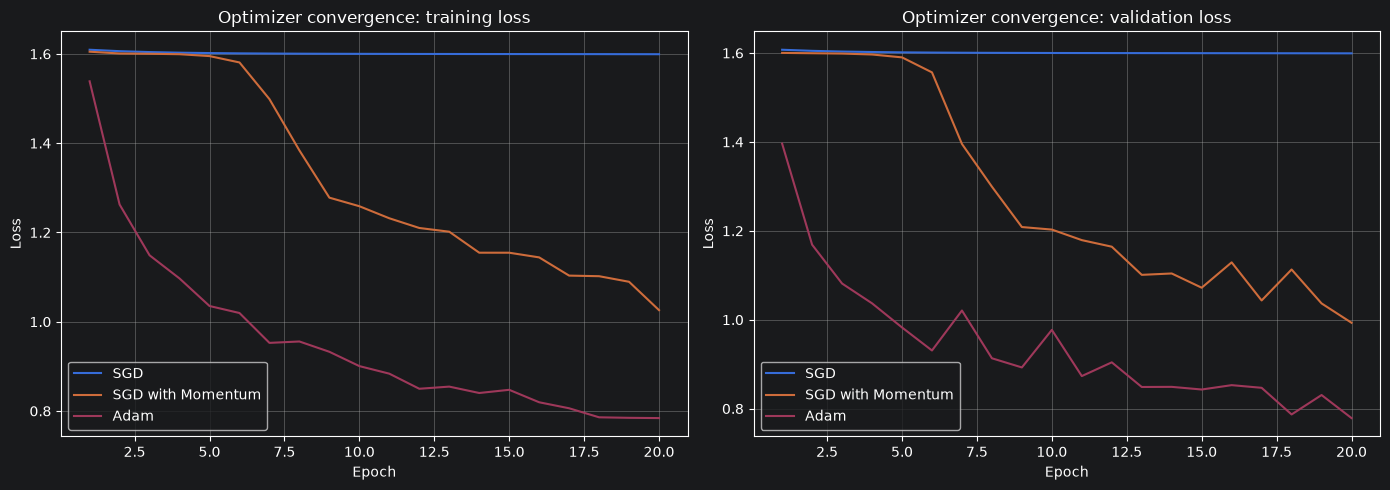

In [39]:
# Step 10: Optimizer comparison — SGD, SGD with Momentum, Adam
optimizers = {
    "SGD": lambda params: optim.SGD(params, lr=0.01),
    "SGD with Momentum": lambda params: optim.SGD(params, lr=0.01, momentum=0.9),
    "Adam": lambda params: optim.Adam(params, lr=0.001)
}

optimizer_results = []
optimizer_histories = {}

# Shared, deterministic weights for all three comparisons.
optimizer_start = fresh_model(model_a, seed=SEED).cpu().state_dict()

for optimizer_name, optimizer_factory in optimizers.items():
    print(f"\nTraining Model A with {optimizer_name}...")
    model = copy.deepcopy(model_a).to(device)
    model.load_state_dict(optimizer_start)
    optimizer = optimizer_factory(model.parameters())

    synchronize_device()
    start_time = time.perf_counter()
    history = train_model(model, optimizer, epochs=OPTIMIZER_EPOCHS,
                          batch_size=BATCH_SIZE, verbose=1, seed=SEED)
    synchronize_device()
    elapsed_time = time.perf_counter() - start_time

    optimizer_histories[optimizer_name] = history
    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Epochs": history.epochs_ran,
        "Final Training Accuracy": history.history["accuracy"][-1],
        "Final Validation Accuracy": history.history["val_accuracy"][-1],
        "Best Val-Loss Epoch": history.best_epoch,
        "Minimum Validation Loss": history.best_val_loss,
        "Best Checkpoint Validation Accuracy": history.best_val_accuracy,
        "Total Training Time (s)": elapsed_time,
        "Average Time per Epoch (s)": elapsed_time / history.epochs_ran
    })

optimizer_df = pd.DataFrame(optimizer_results)
print("\nOptimizer Comparison Results:")
display(optimizer_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in optimizer_histories.items():
    x = range(1, history.epochs_ran + 1)
    axes[0].plot(x, history.history["loss"], label=name)
    axes[1].plot(x, history.history["val_loss"], label=name)
axes[0].set(title="Optimizer convergence: training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Optimizer convergence: validation loss", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 4. Final custom CNN training with best-epoch checkpoints

In [40]:
# Step 11: Train Model A and save/restore its best validation-loss checkpoint
model_a_final = fresh_model(model_a, seed=SEED)
optimizer_a_final = optim.Adam(model_a_final.parameters(), lr=0.001)
scheduler_a = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_a_final, mode="min", factor=0.5, patience=5, min_lr=1e-5
)

synchronize_device()
start_time = time.perf_counter()
history_a = train_model(
    model_a_final, optimizer_a_final, epochs=CUSTOM_EPOCHS,
    batch_size=BATCH_SIZE, verbose=1, scheduler=scheduler_a,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, "model_a_best.pth"), seed=SEED
)
synchronize_device()
time_a = time.perf_counter() - start_time

print(f"\nModel A training time: {time_a:.2f} seconds")
print(f"Average time per epoch: {time_a / history_a.epochs_ran:.2f} seconds")
print(f"Restored best checkpoint from epoch: {history_a.best_epoch}")

Epoch 1/70 - loss: 1.5385 - accuracy: 0.2880 - val_loss: 1.3960 - val_accuracy: 0.3655
Epoch 2/70 - loss: 1.2625 - accuracy: 0.4597 - val_loss: 1.1688 - val_accuracy: 0.5036
Epoch 3/70 - loss: 1.1488 - accuracy: 0.5290 - val_loss: 1.0814 - val_accuracy: 0.5655
Epoch 4/70 - loss: 1.0968 - accuracy: 0.5531 - val_loss: 1.0369 - val_accuracy: 0.5527
Epoch 5/70 - loss: 1.0352 - accuracy: 0.5870 - val_loss: 0.9826 - val_accuracy: 0.5691
Epoch 6/70 - loss: 1.0195 - accuracy: 0.5897 - val_loss: 0.9308 - val_accuracy: 0.6382
Epoch 7/70 - loss: 0.9526 - accuracy: 0.6131 - val_loss: 1.0207 - val_accuracy: 0.5909
Epoch 8/70 - loss: 0.9557 - accuracy: 0.6174 - val_loss: 0.9133 - val_accuracy: 0.6655
Epoch 9/70 - loss: 0.9326 - accuracy: 0.6364 - val_loss: 0.8926 - val_accuracy: 0.6418
Epoch 10/70 - loss: 0.9005 - accuracy: 0.6407 - val_loss: 0.9771 - val_accuracy: 0.5691
Epoch 11/70 - loss: 0.8836 - accuracy: 0.6454 - val_loss: 0.8732 - val_accuracy: 0.6564
Epoch 12/70 - loss: 0.8498 - accuracy: 0.

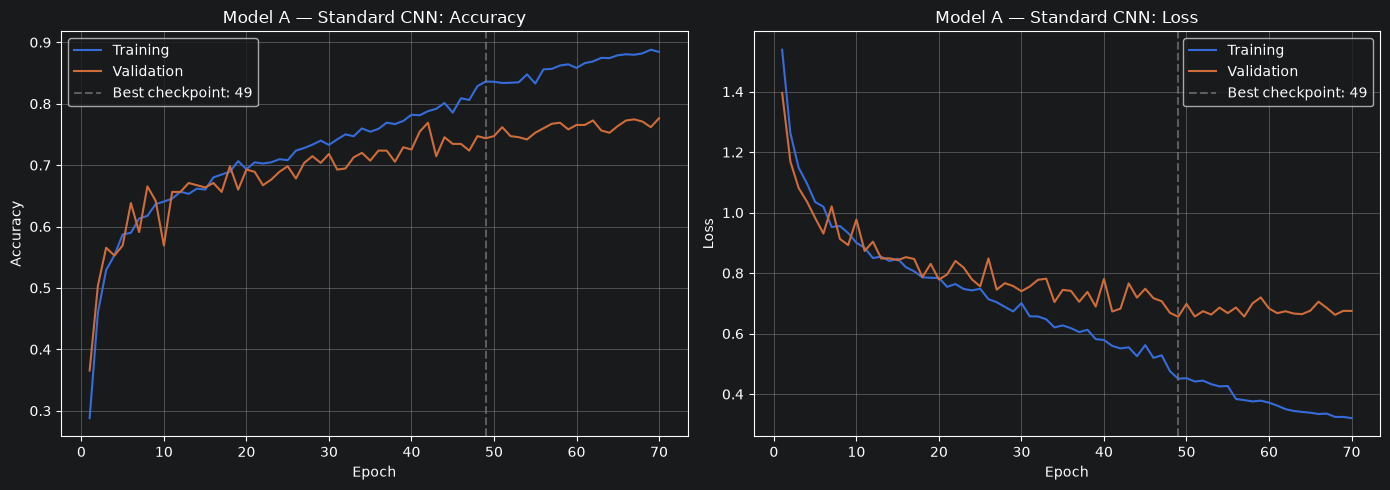

In [41]:
# Step 12: Plot Model A training/validation accuracy and loss
plot_history(history_a, "Model A — Standard CNN")

In [42]:
# Step 13: Train Model B with identical budget, optimizer and checkpoint rule
model_b_final = fresh_model(model_b, seed=SEED)
optimizer_b_final = optim.Adam(model_b_final.parameters(), lr=0.001)
scheduler_b = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_b_final, mode="min", factor=0.5, patience=5, min_lr=1e-5
)

synchronize_device()
start_time = time.perf_counter()
history_b = train_model(
    model_b_final, optimizer_b_final, epochs=CUSTOM_EPOCHS,
    batch_size=BATCH_SIZE, verbose=1, scheduler=scheduler_b,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, "model_b_best.pth"), seed=SEED
)
synchronize_device()
time_b = time.perf_counter() - start_time

print(f"\nModel B training time: {time_b:.2f} seconds")
print(f"Average time per epoch: {time_b / history_b.epochs_ran:.2f} seconds")
print(f"Restored best checkpoint from epoch: {history_b.best_epoch}")

Epoch 1/70 - loss: 1.6094 - accuracy: 0.2293 - val_loss: 1.5973 - val_accuracy: 0.2436
Epoch 2/70 - loss: 1.5125 - accuracy: 0.3239 - val_loss: 1.3215 - val_accuracy: 0.3545
Epoch 3/70 - loss: 1.3100 - accuracy: 0.4056 - val_loss: 1.2894 - val_accuracy: 0.4236
Epoch 4/70 - loss: 1.2833 - accuracy: 0.4223 - val_loss: 1.2692 - val_accuracy: 0.4309
Epoch 5/70 - loss: 1.2215 - accuracy: 0.4800 - val_loss: 1.1583 - val_accuracy: 0.4964
Epoch 6/70 - loss: 1.1827 - accuracy: 0.5025 - val_loss: 1.1422 - val_accuracy: 0.5073
Epoch 7/70 - loss: 1.1636 - accuracy: 0.4990 - val_loss: 1.1225 - val_accuracy: 0.4836
Epoch 8/70 - loss: 1.1323 - accuracy: 0.5298 - val_loss: 1.1007 - val_accuracy: 0.5273
Epoch 9/70 - loss: 1.1171 - accuracy: 0.5302 - val_loss: 1.0810 - val_accuracy: 0.5418
Epoch 10/70 - loss: 1.1015 - accuracy: 0.5450 - val_loss: 1.1247 - val_accuracy: 0.5145
Epoch 11/70 - loss: 1.0879 - accuracy: 0.5481 - val_loss: 1.0485 - val_accuracy: 0.5727
Epoch 12/70 - loss: 1.0682 - accuracy: 0.

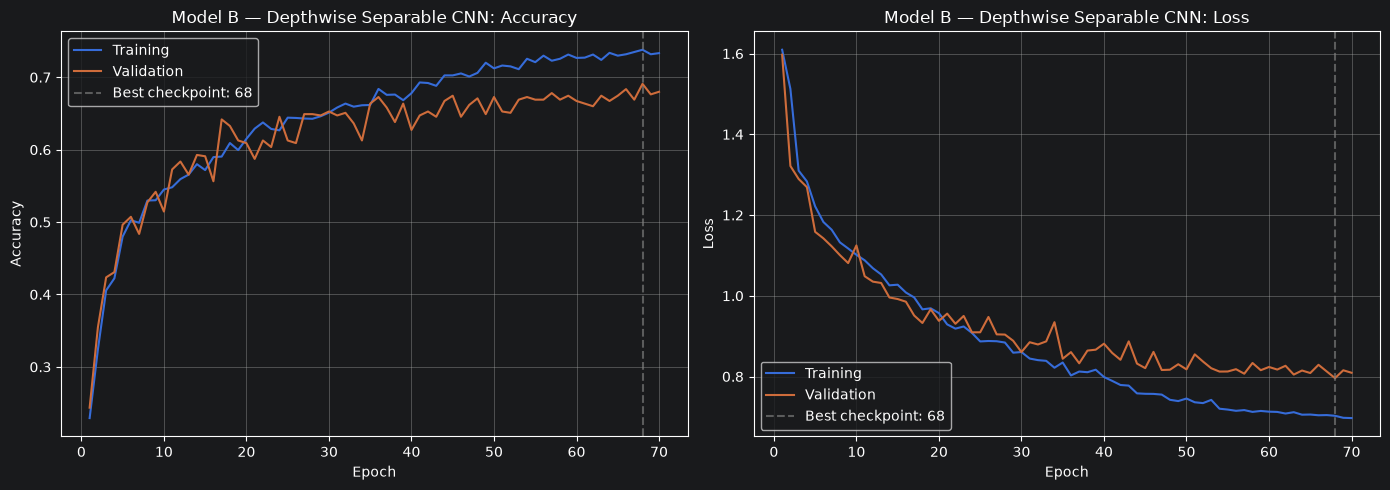

In [43]:
# Step 14: Plot Model B training/validation accuracy and loss
plot_history(history_b, "Model B — Depthwise Separable CNN")

## 5. Final custom CNN test evaluation


Model A - Standard CNN
Accuracy           0.7441
Macro Precision    0.7460
Macro Recall       0.7447

Classification report:
              precision    recall  f1-score   support

   dandelion       0.78      0.76      0.77       135
       daisy       0.87      0.80      0.84        95
      tulips       0.68      0.66      0.67       120
  sunflowers       0.79      0.87      0.83       105
       roses       0.60      0.64      0.62        96

    accuracy                           0.74       551
   macro avg       0.75      0.74      0.74       551
weighted avg       0.75      0.74      0.74       551



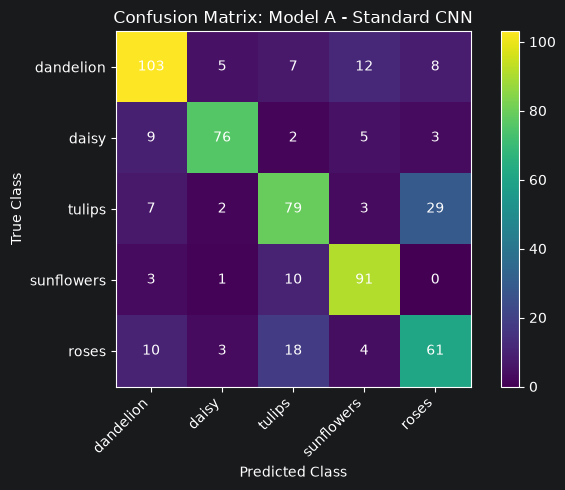


Model B - Lightweight CNN
Accuracy           0.6824
Macro Precision    0.6900
Macro Recall       0.6779

Classification report:
              precision    recall  f1-score   support

   dandelion       0.63      0.77      0.70       135
       daisy       0.83      0.72      0.77        95
      tulips       0.67      0.58      0.62       120
  sunflowers       0.71      0.81      0.76       105
       roses       0.60      0.51      0.55        96

    accuracy                           0.68       551
   macro avg       0.69      0.68      0.68       551
weighted avg       0.69      0.68      0.68       551



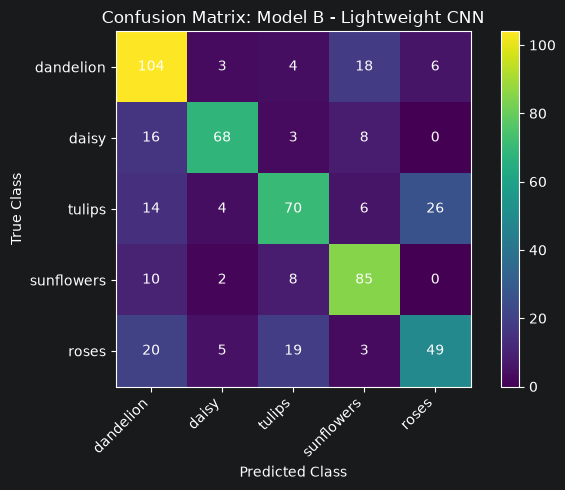


Custom CNN test metrics (BEST checkpoints):


,Accuracy,Macro Precision,Macro Recall
Model A - Standard CNN,0.7441,0.746,0.7447
Model B - Lightweight CNN,0.6824,0.690,0.6779


In [44]:
# Step 15: Evaluate final Model A and Model B on the held-out test split
custom_models = {
    "Model A - Standard CNN": model_a_final,
    "Model B - Lightweight CNN": model_b_final
}

test_results = {}
for model_name, model in custom_models.items():
    test_results[model_name] = evaluate_classifier(
        model, X_test_norm, y_test, model_name
    )

test_results_df = pd.DataFrame.from_dict(test_results, orient="index")
print("\nCustom CNN test metrics (BEST checkpoints):")
display(test_results_df.round(4))

## 6. Parameter counts, architecture details, model size, and MAC estimates

In [45]:
# Step 16: Model profiling (stdlib + PyTorch, no external FLOP package)
def profile_model(model, name, input_shape=(1, 3, 64, 64)):
    stats = {"macs": 0}
    records = []
    hooks = []
    was_training = model.training

    def hook_fn(layer_name):
        def hook(layer, inputs, output):
            params = sum(p.numel() for p in layer.parameters(recurse=False))
            macs = 0
            if isinstance(layer, nn.Conv2d):
                kh, kw = layer.kernel_size
                macs = output.numel() * (layer.in_channels // layer.groups) * kh * kw
            elif isinstance(layer, nn.Linear):
                macs = output.numel() * layer.in_features
            stats["macs"] += macs
            records.append({
                "Layer": layer_name,
                "Type": type(layer).__name__,
                "Output Shape": str(tuple(output.shape)),
                "Parameters": params,
                "MACs": macs
            })
        return hook

    for name_part, layer in model.named_modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear, nn.MaxPool2d,
                              nn.AdaptiveAvgPool2d, nn.BatchNorm2d)):
            hooks.append(layer.register_forward_hook(hook_fn(name_part)))

    try:
        model.eval()
        sample_device = next(model.parameters()).device
        with torch.no_grad():
            model(torch.zeros(input_shape, device=sample_device))
    finally:
        for handle in hooks:
            handle.remove()
        model.train(was_training)

    total_parameters = sum(p.numel() for p in model.parameters())
    trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    path = os.path.join(OUTPUT_DIR, name + "_weights.pth")
    torch.save(model.state_dict(), path)
    size_kib = os.path.getsize(path) / 1024
    summary = {
        "Parameters (total)": total_parameters,
        "Parameters (trainable)": trainable_parameters,
        "FP32 weights (KiB)": total_parameters * 4 / 1024,
        "State_dict on disk (KiB)": size_kib,
        "MACs per image": stats["macs"],
        "MACs (M)": stats["macs"] / 1e6
    }
    return summary, pd.DataFrame(records)

profile_a, layers_a = profile_model(model_a_final, "model_a")
profile_b, layers_b = profile_model(model_b_final, "model_b")

print("Model A layer specifications:")
display(layers_a)
print("Model B layer specifications:")
display(layers_b)
print("Custom model resource comparison:")
resource_df = pd.DataFrame.from_dict({
    "Model A - Standard CNN": profile_a,
    "Model B - Lightweight CNN": profile_b
}, orient="index")
display(resource_df.round(3))

param_reduction = 100 * (1 - profile_b["Parameters (trainable)"] /
                         profile_a["Parameters (trainable)"])
mac_reduction = 100 * (1 - profile_b["MACs per image"] / profile_a["MACs per image"])
print(f"Model B parameter reduction: {param_reduction:.2f}%")
print(f"Model B MAC reduction: {mac_reduction:.2f}%")
assert profile_b["Parameters (trainable)"] <= 100_000

Model A layer specifications:


,Layer,Type,Output Shape,Parameters,MACs
0,0,Conv2d,"(1, 16, 64, 64)",448,1769472
1,2,MaxPool2d,"(1, 16, 32, 32)",0,0
2,3,Conv2d,"(1, 32, 32, 32)",4640,4718592
3,5,MaxPool2d,"(1, 32, 16, 16)",0,0
4,6,Conv2d,"(1, 64, 16, 16)",18496,4718592
5,8,MaxPool2d,"(1, 64, 8, 8)",0,0
6,9,Conv2d,"(1, 128, 8, 8)",73856,4718592
7,11,AdaptiveAvgPool2d,"(1, 128, 1, 1)",0,0
8,13,Linear,"(1, 32)",4128,4096
9,15,Linear,"(1, 5)",165,160


Model B layer specifications:


,Layer,Type,Output Shape,Parameters,MACs
0,0,Conv2d,"(1, 16, 64, 64)",448,1769472
1,2,MaxPool2d,"(1, 16, 32, 32)",0,0
2,3,Conv2d,"(1, 16, 32, 32)",144,147456
3,4,Conv2d,"(1, 32, 32, 32)",544,524288
4,6,MaxPool2d,"(1, 32, 16, 16)",0,0
5,7,Conv2d,"(1, 32, 16, 16)",288,73728
6,8,Conv2d,"(1, 64, 16, 16)",2112,524288
7,10,MaxPool2d,"(1, 64, 8, 8)",0,0
8,11,Conv2d,"(1, 64, 8, 8)",576,36864
9,12,Conv2d,"(1, 128, 8, 8)",8320,524288


Custom model resource comparison:


,Parameters (total),Parameters (trainable),FP32 weights (KiB),State_dict on disk (KiB),MACs per image,MACs (M)
Model A - Standard CNN,101733,101733,397.395,402.265,15929504,15.930
Model B - Lightweight CNN,16725,16725,65.332,71.092,3604640,3.605


Model B parameter reduction: 83.56%
Model B MAC reduction: 77.37%


In [46]:
# Step 17: Custom CNN comparison table — best checkpoint & held-out test metrics
custom_summary = pd.DataFrame([
    {
        "Model": model_name,
        "Trainable Parameters": profile["Parameters (trainable)"],
        "Size on disk (KiB)": profile["State_dict on disk (KiB)"],
        "MACs (M)/image": profile["MACs (M)"],
        "Training Epochs": history.epochs_ran,
        "Best Epoch": history.best_epoch,
        "Minimum Validation Loss": history.best_val_loss,
        "Best Checkpoint Val Accuracy": history.best_val_accuracy,
        "Training Time (s)": duration,
        "Time per Epoch (s)": duration / history.epochs_ran,
        "Test Accuracy": test_results[model_name]["Accuracy"],
        "Macro Precision": test_results[model_name]["Macro Precision"],
        "Macro Recall": test_results[model_name]["Macro Recall"]
    }
    for model_name, profile, history, duration in [
        ("Model A - Standard CNN", profile_a, history_a, time_a),
        ("Model B - Lightweight CNN", profile_b, history_b, time_b)
    ]
])
display(custom_summary.round(4))
custom_summary.to_csv(os.path.join(OUTPUT_DIR, "custom_cnn_comparison.csv"), index=False)

,Model,Trainable Parameters,Size on disk (KiB),MACs (M)/image,Training Epochs,Best Epoch,Minimum Validation Loss,Best Checkpoint Val Accuracy,Training Time (s),Time per Epoch (s),Test Accuracy,Macro Precision,Macro Recall
0,Model A - Standard CNN,101733,402.2646,15.9295,70,49,0.6556,0.7436,81.3359,1.1619,0.7441,0.746,0.7447
1,Model B - Lightweight CNN,16725,71.0918,3.6046,70,68,0.7960,0.6909,62.5688,0.8938,0.6824,0.690,0.6779


## 7. Fine-tune two pretrained lightweight SOTA models

In [47]:
# Step 18: Pretrained-model imports, ImageNet normalization, and builders
from torchvision.models import (mobilenet_v2, efficientnet_b0,
                                MobileNet_V2_Weights, EfficientNet_B0_Weights)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class ImageNetNormalizedDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
        self.normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        return self.normalize(image), label

pretrained_train_dataset = ImageNetNormalizedDataset(custom_train_dataset)
pretrained_val_dataset = ImageNetNormalizedDataset(val_dataset)


def build_pretrained_model(architecture, num_classes):
    try:
        if architecture == "MobileNetV2":
            model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
            model.classifier[1] = nn.Linear(model.classifier[1].in_features,
                                            num_classes)
        elif architecture == "EfficientNet-B0":
            model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
            model.classifier[1] = nn.Linear(model.classifier[1].in_features,
                                            num_classes)
        else:
            raise ValueError(f"Unknown architecture: {architecture}")
    except (OSError, RuntimeError) as exc:
        raise RuntimeError(
            f"Unable to load pretrained {architecture} weights. "
            "Internet access may be required on the first run. "
            "Do not use weights=None: the assignment requires pretrained models."
        ) from exc

    # Freeze pretrained early feature extraction; fine-tune late feature blocks.
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.features[-2:].parameters():
        parameter.requires_grad = True
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    return model.to(device)

print("Pretrained architectures ready: MobileNetV2, EfficientNet-B0")
print("Input resolution for all models: 64 × 64")

Pretrained architectures ready: MobileNetV2, EfficientNet-B0
Input resolution for all models: 64 × 64


Epoch 1/20 - loss: 1.2913 - accuracy: 0.5395 - val_loss: 0.9175 - val_accuracy: 0.7564
Epoch 2/20 - loss: 0.8376 - accuracy: 0.7501 - val_loss: 0.6997 - val_accuracy: 0.7873
Epoch 3/20 - loss: 0.6503 - accuracy: 0.8116 - val_loss: 0.5769 - val_accuracy: 0.8091
Epoch 4/20 - loss: 0.5328 - accuracy: 0.8443 - val_loss: 0.5385 - val_accuracy: 0.8127
Epoch 5/20 - loss: 0.4437 - accuracy: 0.8688 - val_loss: 0.5073 - val_accuracy: 0.8309
Epoch 6/20 - loss: 0.3828 - accuracy: 0.8828 - val_loss: 0.4834 - val_accuracy: 0.8327
Epoch 7/20 - loss: 0.3414 - accuracy: 0.9046 - val_loss: 0.4649 - val_accuracy: 0.8455
Epoch 8/20 - loss: 0.2928 - accuracy: 0.9179 - val_loss: 0.4634 - val_accuracy: 0.8436
Epoch 9/20 - loss: 0.2506 - accuracy: 0.9397 - val_loss: 0.4647 - val_accuracy: 0.8455
Epoch 10/20 - loss: 0.2175 - accuracy: 0.9424 - val_loss: 0.4496 - val_accuracy: 0.8509
Epoch 11/20 - loss: 0.1987 - accuracy: 0.9525 - val_loss: 0.4482 - val_accuracy: 0.8545
Epoch 12/20 - loss: 0.1613 - accuracy: 0.

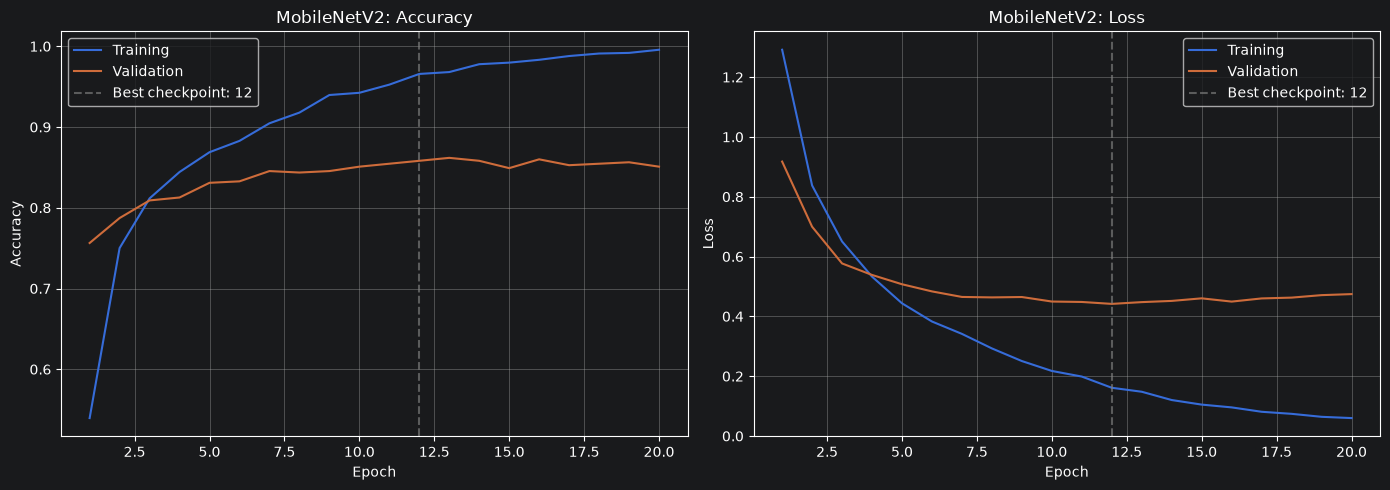

In [48]:
# Step 19: Fine-tune MobileNetV2; restore minimum-validation-loss checkpoint
torch.manual_seed(SEED)
mobilenet_model = build_pretrained_model("MobileNetV2", len(class_names))
mobilenet_optimizer = optim.Adam(
    (p for p in mobilenet_model.parameters() if p.requires_grad), lr=1e-4
)
mobilenet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    mobilenet_optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-6
)

synchronize_device()
start_time = time.perf_counter()
history_mobilenet = train_model(
    mobilenet_model, mobilenet_optimizer, epochs=PRETRAINED_EPOCHS,
    batch_size=BATCH_SIZE, verbose=1,
    training_dataset=pretrained_train_dataset,
    validation_dataset=pretrained_val_dataset,
    scheduler=mobilenet_scheduler,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, "mobilenet_v2_best.pth"), seed=SEED
)
synchronize_device()
time_mobilenet = time.perf_counter() - start_time
print(f"MobileNetV2 training: {time_mobilenet:.2f}s; "
      f"{time_mobilenet / history_mobilenet.epochs_ran:.2f}s/epoch")
plot_history(history_mobilenet, "MobileNetV2")

Epoch 1/20 - loss: 1.3288 - accuracy: 0.4741 - val_loss: 1.0208 - val_accuracy: 0.6691
Epoch 2/20 - loss: 0.8600 - accuracy: 0.7275 - val_loss: 0.7660 - val_accuracy: 0.7491
Epoch 3/20 - loss: 0.6655 - accuracy: 0.7871 - val_loss: 0.6515 - val_accuracy: 0.7727
Epoch 4/20 - loss: 0.5389 - accuracy: 0.8311 - val_loss: 0.6070 - val_accuracy: 0.7891
Epoch 5/20 - loss: 0.4579 - accuracy: 0.8544 - val_loss: 0.5701 - val_accuracy: 0.8055
Epoch 6/20 - loss: 0.3983 - accuracy: 0.8743 - val_loss: 0.5579 - val_accuracy: 0.8091
Epoch 7/20 - loss: 0.3603 - accuracy: 0.8906 - val_loss: 0.5425 - val_accuracy: 0.8145
Epoch 8/20 - loss: 0.2983 - accuracy: 0.9120 - val_loss: 0.5447 - val_accuracy: 0.8073
Epoch 9/20 - loss: 0.2707 - accuracy: 0.9190 - val_loss: 0.5449 - val_accuracy: 0.8073
Epoch 10/20 - loss: 0.2405 - accuracy: 0.9327 - val_loss: 0.5362 - val_accuracy: 0.8127
Epoch 11/20 - loss: 0.2175 - accuracy: 0.9393 - val_loss: 0.5383 - val_accuracy: 0.8218
Epoch 12/20 - loss: 0.1977 - accuracy: 0.

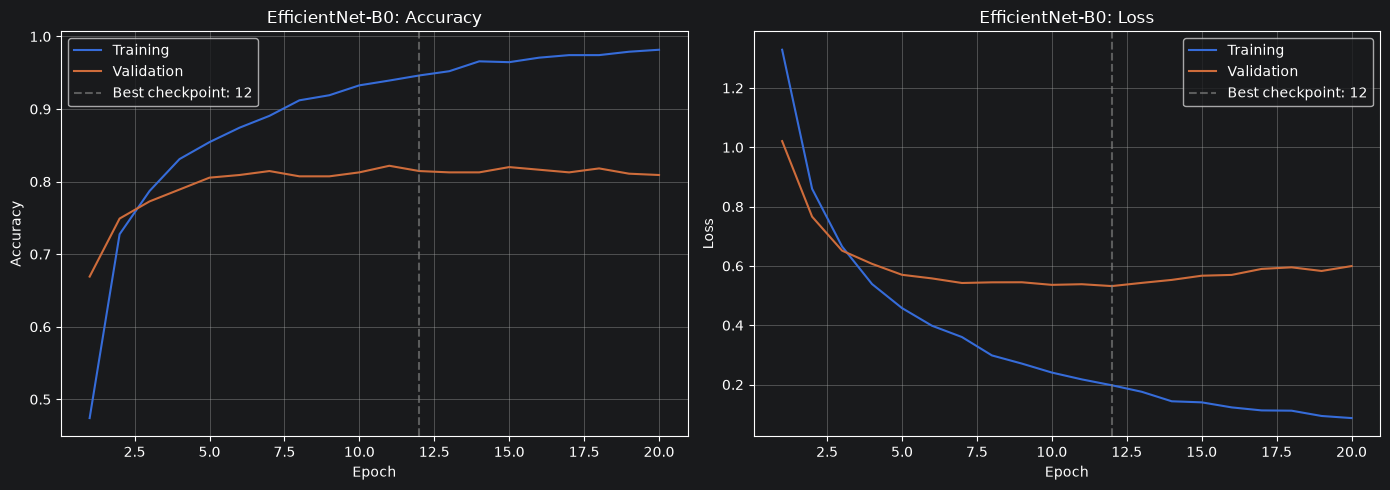

In [49]:
# Step 20: Fine-tune EfficientNet-B0; restore minimum-validation-loss checkpoint
torch.manual_seed(SEED)
efficientnet_model = build_pretrained_model("EfficientNet-B0", len(class_names))
efficientnet_optimizer = optim.Adam(
    (p for p in efficientnet_model.parameters() if p.requires_grad), lr=1e-4
)
efficientnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    efficientnet_optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-6
)

synchronize_device()
start_time = time.perf_counter()
history_efficientnet = train_model(
    efficientnet_model, efficientnet_optimizer, epochs=PRETRAINED_EPOCHS,
    batch_size=BATCH_SIZE, verbose=1,
    training_dataset=pretrained_train_dataset,
    validation_dataset=pretrained_val_dataset,
    scheduler=efficientnet_scheduler,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, "efficientnet_b0_best.pth"), seed=SEED
)
synchronize_device()
time_efficientnet = time.perf_counter() - start_time
print(f"EfficientNet-B0 training: {time_efficientnet:.2f}s; "
      f"{time_efficientnet / history_efficientnet.epochs_ran:.2f}s/epoch")
plot_history(history_efficientnet, "EfficientNet-B0")

## 8. SOTA test-set evaluation and memory/computation audit


MobileNetV2
Accuracy           0.8022
Macro Precision    0.8019
Macro Recall       0.7993

Classification report:
              precision    recall  f1-score   support

   dandelion       0.85      0.83      0.84       135
       daisy       0.82      0.78      0.80        95
      tulips       0.76      0.78      0.77       120
  sunflowers       0.78      0.89      0.83       105
       roses       0.79      0.72      0.75        96

    accuracy                           0.80       551
   macro avg       0.80      0.80      0.80       551
weighted avg       0.80      0.80      0.80       551



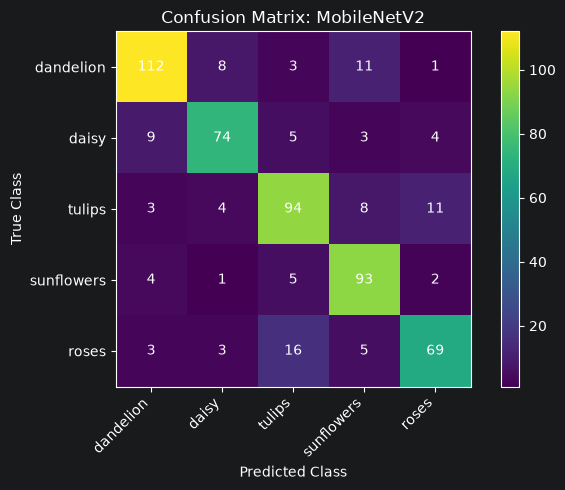


EfficientNet-B0
Accuracy           0.8294
Macro Precision    0.8262
Macro Recall       0.8298

Classification report:
              precision    recall  f1-score   support

   dandelion       0.89      0.81      0.85       135
       daisy       0.81      0.84      0.82        95
      tulips       0.82      0.82      0.82       120
  sunflowers       0.83      0.89      0.86       105
       roses       0.77      0.78      0.78        96

    accuracy                           0.83       551
   macro avg       0.83      0.83      0.83       551
weighted avg       0.83      0.83      0.83       551



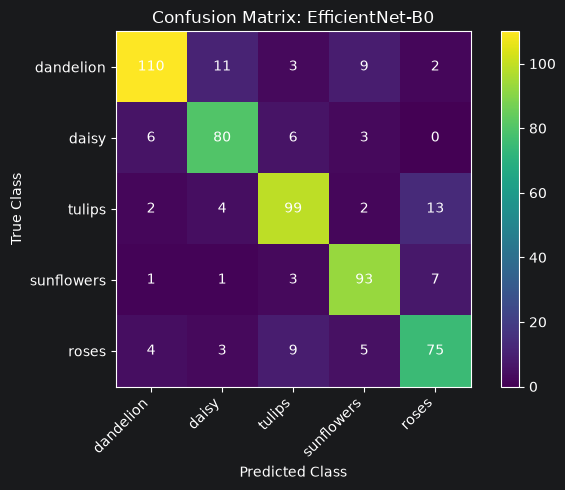

,Accuracy,Macro Precision,Macro Recall
MobileNetV2,0.8022,0.8019,0.7993
EfficientNet-B0,0.8294,0.8262,0.8298


In [50]:
# Step 21: Test metrics, precision/recall, and confusion matrices for SOTA CNNs
sota_models = {
    "MobileNetV2": mobilenet_model,
    "EfficientNet-B0": efficientnet_model
}
sota_test_results = {}
for model_name, model in sota_models.items():
    sota_test_results[model_name] = evaluate_classifier(
        model, X_test_norm, y_test, model_name,
        mean=IMAGENET_MEAN, std=IMAGENET_STD
    )

display(pd.DataFrame.from_dict(sota_test_results, orient="index").round(4))

In [51]:
# Step 22: Full pretrained model sizes and MACs
profile_mobilenet, layers_mobilenet = profile_model(mobilenet_model, "mobilenet_v2")
profile_efficientnet, layers_efficientnet = profile_model(efficientnet_model, "efficientnet_b0")

sota_summary = pd.DataFrame([
    {
        "Model": name,
        "Total Parameters": profile["Parameters (total)"],
        "Trainable Parameters": profile["Parameters (trainable)"],
        "Model Size (MB)": profile["State_dict on disk (KiB)"] / 1024,
        "MACs (M)/image": profile["MACs (M)"],
        "Epochs": hist.epochs_ran,
        "Best Epoch": hist.best_epoch,
        "Minimum Validation Loss": hist.best_val_loss,
        "Training Time per Epoch (s)": duration / hist.epochs_ran,
        "Test Accuracy": sota_test_results[name]["Accuracy"],
        "Macro Precision": sota_test_results[name]["Macro Precision"],
        "Macro Recall": sota_test_results[name]["Macro Recall"]
    }
    for name, profile, hist, duration in [
        ("MobileNetV2", profile_mobilenet, history_mobilenet, time_mobilenet),
        ("EfficientNet-B0", profile_efficientnet,
         history_efficientnet, time_efficientnet)
    ]
])
display(sota_summary.round(4))
sota_summary.to_csv(os.path.join(OUTPUT_DIR, "pretrained_sota_comparison.csv"), index=False)

,Model,Total Parameters,Trainable Parameters,Model Size (MB),MACs (M)/image,Epochs,Best Epoch,Minimum Validation Loss,Training Time per Epoch (s),Test Accuracy,Macro Precision,Macro Recall
0,MobileNetV2,2230277,892485,8.7451,24.4549,20,12,0.4417,0.8874,0.8022,0.8019,0.7993
1,EfficientNet-B0,4013953,1135797,15.6024,31.9730,20,12,0.5320,1.3027,0.8294,0.8262,0.8298


## 9. Final four-model comparison and trade-offs

,Model,Total Parameters,Trainable Parameters,Model Size (KiB),Model Size (MB),MACs (M)/image,Epochs,Best Checkpoint Epoch,Minimum Validation Loss,Training Time per Epoch (s),Test Accuracy,Macro Precision,Macro Recall
0,Model A - Standard CNN,101733,101733,402.2646,0.3928,15.9295,70,49,0.6556,1.1619,0.7441,0.7460,0.7447
1,Model B - Lightweight CNN,16725,16725,71.0918,0.0694,3.6046,70,68,0.7960,0.8938,0.6824,0.6900,0.6779
2,MobileNetV2,2230277,892485,8955.0107,8.7451,24.4549,20,12,0.4417,0.8874,0.8022,0.8019,0.7993
3,EfficientNet-B0,4013953,1135797,15976.8896,15.6024,31.9730,20,12,0.5320,1.3027,0.8294,0.8262,0.8298


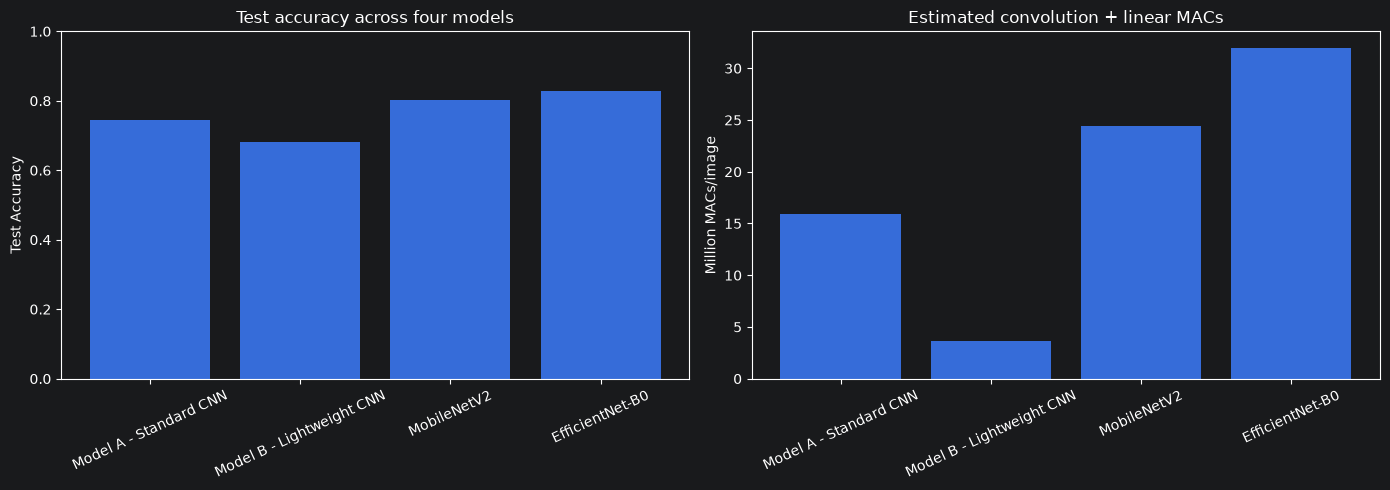

In [52]:
# Step 23: Final four-way comparison (same 64x64 held-out test split)
all_entries = [
    ("Model A - Standard CNN", profile_a, history_a, time_a, test_results["Model A - Standard CNN"]),
    ("Model B - Lightweight CNN", profile_b, history_b, time_b, test_results["Model B - Lightweight CNN"]),
    ("MobileNetV2", profile_mobilenet, history_mobilenet, time_mobilenet,
     sota_test_results["MobileNetV2"]),
    ("EfficientNet-B0", profile_efficientnet, history_efficientnet, time_efficientnet,
     sota_test_results["EfficientNet-B0"])
]

final_comparison = pd.DataFrame([{
    "Model": name,
    "Total Parameters": profile["Parameters (total)"],
    "Trainable Parameters": profile["Parameters (trainable)"],
    "Model Size (KiB)": profile["State_dict on disk (KiB)"],
    "Model Size (MB)": profile["State_dict on disk (KiB)"] / 1024,
    "MACs (M)/image": profile["MACs (M)"],
    "Epochs": hist.epochs_ran,
    "Best Checkpoint Epoch": hist.best_epoch,
    "Minimum Validation Loss": hist.best_val_loss,
    "Training Time per Epoch (s)": duration / hist.epochs_ran,
    "Test Accuracy": result["Accuracy"],
    "Macro Precision": result["Macro Precision"],
    "Macro Recall": result["Macro Recall"]
} for name, profile, hist, duration, result in all_entries])

display(final_comparison.round(4))
final_comparison.to_csv(os.path.join(OUTPUT_DIR, "final_four_model_comparison.csv"),
                        index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(final_comparison["Model"], final_comparison["Test Accuracy"])
axes[0].set(ylabel="Test Accuracy", title="Test accuracy across four models", ylim=(0, 1))
axes[1].bar(final_comparison["Model"], final_comparison["MACs (M)/image"])
axes[1].set(ylabel="Million MACs/image", title="Estimated convolution + linear MACs")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()